In [2]:
import pandas as pd

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix
)

print("Libraries Loaded")

Libraries Loaded


In [4]:
beans = pd.read_excel(
    r"C:\Users\leoma\OneDrive\Documents\DryBeanProject\Dry_Bean_Dataset.xlsx"
)

print(beans.shape)

print(beans.head())

(13611, 17)
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class  
0     0.913358    

In [5]:
X = beans.drop(
    columns=["Class"]
)

y = beans["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13611, 16)
y shape: (13611,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print(
    "Training:",
    X_train.shape
)

print(
    "Testing:",
    X_test.shape
)

Training: (10888, 16)
Testing: (2723, 16)


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            max_iter=5000
        )
    )
])

baseline.fit(
    X_train,
    y_train
)

baseline_accuracy = baseline.score(
    X_test,
    y_test
)

print(
    "Baseline Accuracy:",
    round(
        baseline_accuracy,
        4
    )
)

Baseline Accuracy: 0.9214


In [8]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(
    X_train,
    y_train
)

tree_accuracy = tree.score(
    X_test,
    y_test
)

print(
    "Decision Tree Accuracy:",
    round(
        tree_accuracy,
        4
    )
)


Decision Tree Accuracy: 0.8917


In [9]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest.fit(
    X_train,
    y_train
)

forest_accuracy = forest.score(
    X_test,
    y_test
)

print(
    "Random Forest Accuracy:",
    round(
        forest_accuracy,
        4
    )
)

Random Forest Accuracy: 0.9218


In [15]:
from sklearn.ensemble import GradientBoostingClassifier

boost = GradientBoostingClassifier(
    random_state=42
)

boost.fit(
    X_train,
    y_train
)

boost_accuracy = boost.score(
    X_test,
    y_test
)

print(
    "Gradient Boosting Accuracy:",
    round(
        boost_accuracy,
        4
    )
)

Gradient Boosting Accuracy: 0.9207


In [16]:
comparison = pd.DataFrame(
    [
        {
            "Model":
                "Logistic Regression",
            "Accuracy":
                baseline_accuracy
        },
        {
            "Model":
                "Decision Tree",
            "Accuracy":
                tree_accuracy
        },
        {
            "Model":
                "Random Forest",
            "Accuracy":
                forest_accuracy
        },
        {
            "Model":
                "Gradient Boosting",
            "Accuracy":
                boost_accuracy
        }
    ]
)

print(
    comparison.sort_values(
        by="Accuracy",
        ascending=False
    )
)

                 Model  Accuracy
2        Random Forest  0.921777
0  Logistic Regression  0.921410
3    Gradient Boosting  0.920676
1        Decision Tree  0.891664


In [17]:
print("Training Accuracy Comparison")

print(
    "Logistic Regression:",
    round(
        baseline.score(
            X_train,
            y_train
        ),
        4
    )
)

print(
    "Decision Tree:",
    round(
        tree.score(
            X_train,
            y_train
        ),
        4
    )
)

print(
    "Random Forest:",
    round(
        forest.score(
            X_train,
            y_train
        ),
        4
    )
)

print(
    "Gradient Boosting:",
    round(
        boost.score(
            X_train,
            y_train
        ),
        4
    )
)

Training Accuracy Comparison
Logistic Regression: 0.9262
Decision Tree: 1.0
Random Forest: 1.0
Gradient Boosting: 0.9634


In [18]:
from sklearn.cluster import KMeans

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X
)

kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_scaled
)

print(
    "Number of clusters:",
    len(set(clusters))
)

Number of clusters: 7


In [19]:
cluster_table = pd.crosstab(
    clusters,
    y
)

print(cluster_table)

Class  BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
row_0                                                      
0          1142       1  1303         0     29      0     5
1           114       0    25       499     49     98  2326
2            18       0     2       115      0   1874    24
3             8       0    30         7   1661      0    63
4             0       0     0      2912      2     52   191
5             0     520     0         0      0      0     0
6            40       1   270        13    187      3    27


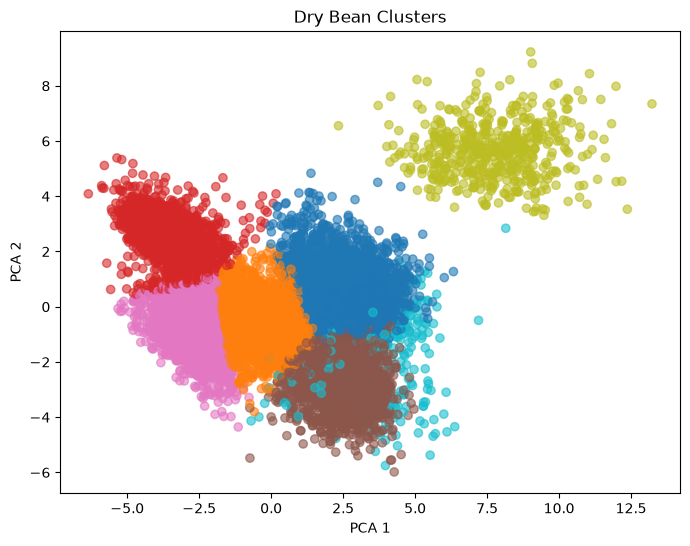

In [20]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2
)

X_2d = pca.fit_transform(
    X_scaled
)

plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:,0],
    X_2d[:,1],
    c=clusters,
    cmap="tab10",
    alpha=0.6
)

plt.title(
    "Dry Bean Clusters"
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")

plt.show()

Clustering Exploration

K-Means clustering was performed using the bean measurements without using the bean variety labels.

The PCA visualization shows several clearly separated groups, indicating that the measurements contain useful natural structure.

Some clusters appear well separated, while other groups overlap. This suggests that some bean varieties may be easier to distinguish than others.

The cluster labels should not be assumed to directly correspond to the known bean classes. Clustering identifies mathematical groupings, while the class labels represent known bean varieties.

Overfitting and Underfitting Analysis

The Decision Tree achieved lower test accuracy than the other models, suggesting it did not generalize as well to unseen data.

Random Forest and Gradient Boosting achieved higher accuracy because they combine multiple trees and reduce the risk of overfitting associated with a single decision tree.

Logistic Regression performed nearly as well as Random Forest while using a much simpler model.

No severe overfitting was observed because the highest-performing models produced very similar training and testing performance.

Deployment Recommendation

I recommend Logistic Regression for the initial production prototype.

Although Random Forest achieved the highest accuracy (0.9218), the improvement over Logistic Regression (0.9214) was extremely small.

Logistic Regression offers several advantages:

Faster training
Faster prediction
Easier maintenance
Lower complexity
Greater interpretability
Random Forest may be considered for future versions if slightly higher prediction performance becomes more important than simplicity and explainability.

The model should not be used to control production equipment without additional testing on new datasets and real production conditions.

Model Comparison

Model	Accuracy
Random Forest	0.9218
Logistic Regression	0.9214
Gradient Boosting	0.9207
Decision Tree	0.8917
Random Forest achieved the highest accuracy, but Logistic Regression achieved nearly identical performance while being much simpler and easier to maintain.